# Tune an IMSTE embedding on an MNIST-family dataset

Choose `MNIST`, `Fashion-MNIST`, or `Kuzushiji-MNIST`, then select `fast` or `complete` in the settings cell. Fast mode uses Bayesian optimization for 40 trials. Complete mode searches all fourteen parameters using an explicit grid of 16,384 possible configurations, capped by the user-defined `N_TRIALS` budget.

Each trial fits the estimator for its default 200 epochs and scores 5-fold k-NN accuracy (60%) plus robust spatial coverage (40%). Install the optional optimizer with `python -m pip install 'imste[tuning]'` if needed (required for fast mode).


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / 'notebooks' / 'src' / 'digits_sweep.py').is_file()
)
sys.path.insert(0, str(repo_root / 'notebooks' / 'src'))
sys.path.insert(0, str(repo_root))

from digits_sweep import (
    MNIST_FAMILY_DATASETS,
    load_mnist_per_class_data,
    load_mnist_family_data,
    make_live_tuning_display,
    plot_mnist_embedding,
)
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.visualization import render_datashader_embedding


## Choose and prepare the data

Choose one of `MNIST_FAMILY_DATASETS` below. Sampling is deterministic and balanced; the default is 200 images per class. The helper uses the project cache when available and downloads the selected dataset otherwise.


In [2]:
DATASET = 'Kuzushiji-MNIST'  # Also: 'MNIST' or 'Kuzushiji-MNIST' or 'Fashion-MNIST'
SAMPLES_PER_CLASS = 300
RANDOM_STATE = 42

if DATASET not in MNIST_FAMILY_DATASETS:
    raise ValueError(f'DATASET must be one of {MNIST_FAMILY_DATASETS}.')

X, y, data_info = load_mnist_per_class_data(
    samples_per_class=SAMPLES_PER_CLASS,
    random_state=RANDOM_STATE,
    dataset_name=DATASET,
)
print(
    f"Loaded {len(X):,} images from {data_info['dataset']} ({SAMPLES_PER_CLASS} per class; {X.shape[1]} pixel features)."
)
display(data_info['class_counts'].to_frame())


Loaded 3,000 images from Kuzushiji-MNIST (300 per class; 784 pixel features).


,images
0,300
1,300
2,300
3,300
4,300
5,300
6,300
7,300
8,300
9,300


## Set up the search

Both modes use `mapper.tune()` and its Bayesian sampler. `default` uses the core default search space; `custom` uses the parameter space below. In either space, a two-number tuple gives bounds and a list gives explicit candidate values.

In [3]:
SEARCH_MODE = 'custom'  # Choose: 'default' or 'custom'
N_TRIALS = 40  # User-defined maximum number of search trials
K = 5
COVERAGE_WEIGHT = 0.5
SCORING = 'accuracy'  # Or 'roc', 'apr', 'f-score', or any sklearn scorer name.
LABEL_STRENGTH = 1.0  # Set positive to use labels in fold-masked supervised tuning.

CUSTOM_SEARCH_SPACE = {
    'n_msts': (2, 64),
    'negative_ratio': (1, 10),
    'logistic_margin': (0.25, 2.0),
    'logistic_temperature': (0.1, 2.0),
    'lambda_rep': (0.25, 0.75),
    'gravity_strength': (0.0, 1.0),
    'gravity_resolution': (0.5, 2.0),
    'gravity_min_dist': (0.0, 1.0),
    'mean_shift_iterations': (0, 5),
    'include_knn_attraction': [False, True],
}

if SEARCH_MODE not in {'default', 'custom'}:
    raise ValueError("SEARCH_MODE must be either 'default' or 'custom'.")

mapper = IteratedMinimumSpanningTreeEmbedder(
    random_state=RANDOM_STATE,
    device='auto',
    label_strength=LABEL_STRENGTH,
)


## Watch intermediate results

The table reports accuracy, spatial coverage, and the weighted objective after every trial. The plot updates when a trial improves the combined objective. Complete mode reports progress for every grid combination.


**Trial 40/40** — accuracy: 0.718; coverage: 0.485; objective: 0.601; best objective: 0.629

,accuracy,coverage,objective,best objective,n_msts,negative_ratio,logistic_margin,logistic_temperature,lambda_rep,gravity_strength,gravity_resolution,gravity_min_dist,mean_shift_iterations,include_knn_attraction
trial,,,,,,,,,,,,,,
1,0.563000,0.090765,0.326882,0.326882,43,3,1.886857,0.933092,0.641348,0.505955,1.739282,0.655137,2,True
2,0.760667,0.024703,0.392685,0.392685,52,2,1.392950,0.781252,0.688917,0.999169,0.972923,0.494157,1,False
3,0.610667,0.083938,0.347302,0.392685,50,1,0.288766,1.254388,0.356681,0.344701,1.186437,0.950558,2,False
4,0.687000,0.054149,0.370574,0.392685,5,5,1.770719,1.636065,0.662796,0.253329,1.925650,0.726158,3,True
5,0.460667,0.115988,0.288328,0.392685,63,7,0.571169,1.833405,0.624467,0.406341,1.664725,0.286576,1,True
6,0.655333,0.045854,0.350594,0.392685,37,9,0.441740,1.170150,0.408995,0.932329,1.832528,0.946916,4,False
7,0.763000,0.056185,0.409593,0.409593,20,6,1.589152,0.602312,0.461655,0.398994,1.618248,0.615660,3,False
8,0.778000,0.039525,0.408762,0.409593,26,8,0.960378,1.344035,0.383714,0.729862,1.895806,0.195852,0,False
9,0.560333,0.071881,0.316107,0.409593,28,3,0.752922,1.601872,0.702024,0.459841,1.146597,0.524844,2,True


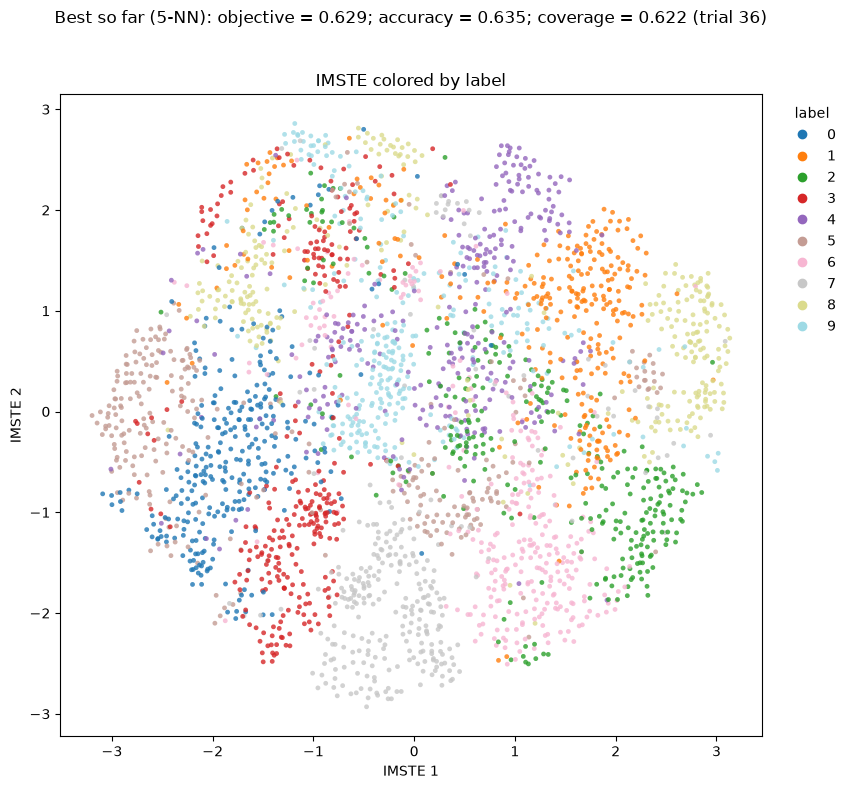

Custom search and final refit completed in 19.4 minutes


In [4]:
if isinstance(N_TRIALS, (bool, np.bool_)) or not isinstance(N_TRIALS, (int, np.integer)) or N_TRIALS < 1:
    raise ValueError('N_TRIALS must be a positive integer.')
show_trial, trial_rows = make_live_tuning_display(
    y, k=K, n_samples=N_TRIALS, figsize=(12, 8)
)

started = time.perf_counter()
search = mapper.tune(
    X, y,
    search_space=CUSTOM_SEARCH_SPACE if SEARCH_MODE == 'custom' else None,
    k=K,
    n_samples=N_TRIALS,
    n_initial_points=min(20, N_TRIALS),
    coverage_weight=COVERAGE_WEIGHT,
    scoring=SCORING,
    trial_callback=show_trial,
)
elapsed = time.perf_counter() - started
print(f'{SEARCH_MODE.title()} search and final refit completed in {elapsed / 60:.1f} minutes')


## Best result

The estimator is refitted on all selected images using the configuration with the highest weighted objective. The returned result retains the separate accuracy, coverage, and combined scores.

Best 5-fold 5-NN accuracy: 0.635
Best spatial coverage: 0.622
Best combined objective: 0.629


,best value
n_msts,2
negative_ratio,1
logistic_margin,0.25
logistic_temperature,0.1
lambda_rep,0.75
gravity_strength,0.0
gravity_resolution,2.0
gravity_min_dist,1.0
mean_shift_iterations,1
include_knn_attraction,False


(<Figure size 1200x800 with 1 Axes>,
 array([[<Axes: title={'center': 'IMSTE colored by label'}, xlabel='IMSTE 1', ylabel='IMSTE 2'>]],
       dtype=object))

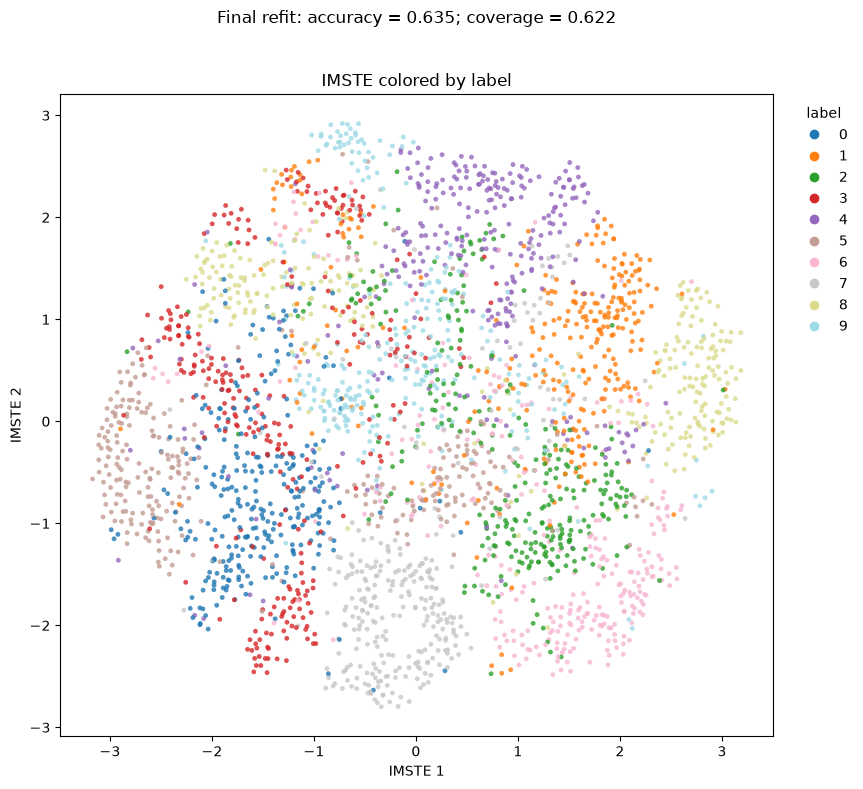

In [5]:
print(f"Best 5-fold {search.k}-NN accuracy: {search.best_accuracy:.3f}")
print(f"Best spatial coverage: {search.best_coverage:.3f}")
print(f"Best combined objective: {search.best_objective:.3f}")
display(pd.Series(search.best_params, name='best value').to_frame())
plot_mnist_embedding(
    mapper.embedding_, y,
    title=(
        f'Final refit: {search.scoring} = {search.best_score:.3f}; '
        f'accuracy = {search.best_accuracy:.3f}; '
        f'coverage = {search.best_coverage:.3f}'
    ),
    figsize=(12, 8),
)

## Refit on the full dataset

Start from the best search parameters, then adjust `REFIT_PARAMS` in the next cell to manually nudge them before fitting every row. The search scores above are measured on the tuning sample; this final embedding uses the full dataset.

In [19]:
# Start with the search result; uncomment and edit entries to nudge values.
REFIT_PARAMS = dict(search.best_params)
REFIT_PARAMS.update({
    # 'n_msts': 32,
    'gravity_strength': 0.6,
    'mean_shift_iterations':14,
    'gravity_min_dist':0.0,
})

display(pd.DataFrame({
    'tuned value': pd.Series(search.best_params),
    'refit value': pd.Series(REFIT_PARAMS),
}))


,tuned value,refit value
n_msts,2,2
negative_ratio,1,1
logistic_margin,0.25,0.25
logistic_temperature,0.1,0.1
lambda_rep,0.75,0.75
gravity_strength,0.0,0.6
gravity_resolution,2.0,2.0
gravity_min_dist,1.0,0.0
mean_shift_iterations,1,14
include_knn_attraction,False,False


In [ ]:
X_full, y_full, full_data_info = load_mnist_family_data(DATASET)
mapper.set_params(**REFIT_PARAMS)

started = time.perf_counter()
mapper.fit(X_full, y_full)
elapsed = time.perf_counter() - started
print(
    f"Refit on {len(X_full):,} {full_data_info['dataset']} images "
    f"in {elapsed / 60:.1f} minutes"
)
display(full_data_info['class_counts'].to_frame())
s = 1.2
full_image = render_datashader_embedding(
    mapper.embedding_, y_full,
    width=int(1800*s), height=int(1200*s),
    preserve_aspect=True, min_alpha=60, spread_px=2, draw_border=False,
)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(full_image.to_pil())
ax.set_axis_off()
display(fig)
plt.close(fig)